In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import string
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [2]:
DATASET_PATH = '/kaggle/input/datasets/axxxellll/indonesia-cognitive-distortion/COGNITIVE DISTORTION DATASET IN BAHASA INDONESIA COMPLETE.csv'

df = pd.read_csv(DATASET_PATH)
df.head()

,TEXT,DATA STATUS,FIRST ANNOTATOR,SECOND ANNOTATOR
0,ketika saya sudah berusaha semaksimal mungkin ...,RAW-ORI,All-or-nothing,All-or-nothing
1,Saya ketika SD hingga SMP dulu beranggapan bah...,RAW-ORI,All-or-nothing,All-or-nothing
2,Saya berfikir jika tidak lolos MBKM maka masa ...,RAW-ORI,All-or-nothing,All-or-nothing
3,"Di desa saya dulu ada dua kelompok pertemanan,...",RAW-ORI,All-or-nothing,All-or-nothing
4,Saya hanya berteman dengan orang yang tidak me...,RAW-ORI,All-or-nothing,All-or-nothing


In [3]:
df['TEXT'] = df['TEXT'].apply(lambda x: x.replace('$',''))

In [4]:
df['FIRST ANNOTATOR'].value_counts()

FIRST ANNOTATOR
No Distortion                    2246
Labeling                          390
Mind Reading                      385
Should statement                  371
Personalization and Blame         284
Discounting the positives         241
Overgeneralization                215
All-or-nothing                    200
Mental filter                     200
Emotional Reasoning               200
Magnification or Minimization     200
Fortune-telling                    60
Name: count, dtype: int64

In [5]:
df['SECOND ANNOTATOR'].value_counts()

SECOND ANNOTATOR
No Distortion                    2246
Labeling                          390
Mind Reading                      385
Should statement                  371
Personalization and Blame         284
Discounting the positives         241
Overgeneralization                215
All-or-nothing                    200
Mental filter                     200
Emotional Reasoning               200
Magnification or Minimization     200
Fortune-telling                    60
Name: count, dtype: int64

In [6]:
enc = LabelEncoder()

num_labels = enc.fit_transform(df['FIRST ANNOTATOR'])
df['LABEL'] = num_labels

In [7]:
df.head()

,TEXT,DATA STATUS,FIRST ANNOTATOR,SECOND ANNOTATOR,LABEL
0,ketika saya sudah berusaha semaksimal mungkin ...,RAW-ORI,All-or-nothing,All-or-nothing,0
1,Saya ketika SD hingga SMP dulu beranggapan bah...,RAW-ORI,All-or-nothing,All-or-nothing,0
2,Saya berfikir jika tidak lolos MBKM maka masa ...,RAW-ORI,All-or-nothing,All-or-nothing,0
3,"Di desa saya dulu ada dua kelompok pertemanan,...",RAW-ORI,All-or-nothing,All-or-nothing,0
4,Saya hanya berteman dengan orang yang tidak me...,RAW-ORI,All-or-nothing,All-or-nothing,0


In [8]:
num_labels = len(enc.classes_)
label2id = dict(zip(enc.classes_, range(num_labels)))
id2label = dict(enumerate(enc.classes_))

print("Label Mapping:", label2id)

Label Mapping: {'All-or-nothing': 0, 'Discounting the positives': 1, 'Emotional Reasoning': 2, 'Fortune-telling': 3, 'Labeling': 4, 'Magnification or Minimization': 5, 'Mental filter': 6, 'Mind Reading': 7, 'No Distortion': 8, 'Overgeneralization': 9, 'Personalization and Blame': 10, 'Should statement': 11}


In [9]:
from transformers import AutoTokenizer, AutoModel, TrainingArguments, AutoModelForSequenceClassification
from transformers import Trainer, EarlyStoppingCallback
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [10]:
tokenizer = AutoTokenizer.from_pretrained("indobenchmark/indobert-base-p1")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [11]:
X = df['TEXT'].apply(lambda x: x.replace('$',''))
y = df['LABEL']

x_train, x_test, y_train, y_test = train_test_split(X,y, random_state=42, test_size=0.1)

In [12]:
def tokenize(batch):
    return tokenizer(batch['TEXT'], padding=True, truncation=True, max_length=128)


In [13]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, average="weighted"),
        "precision": precision_score(labels, predictions, average="weighted"),
        "recall": recall_score(labels, predictions, average="weighted")
    }

2026-05-21 09:02:31.890627: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779354152.434673      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779354152.605857      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779354153.696226      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779354153.696270      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779354153.696273      23 computation_placer.cc:177] computation placer alr

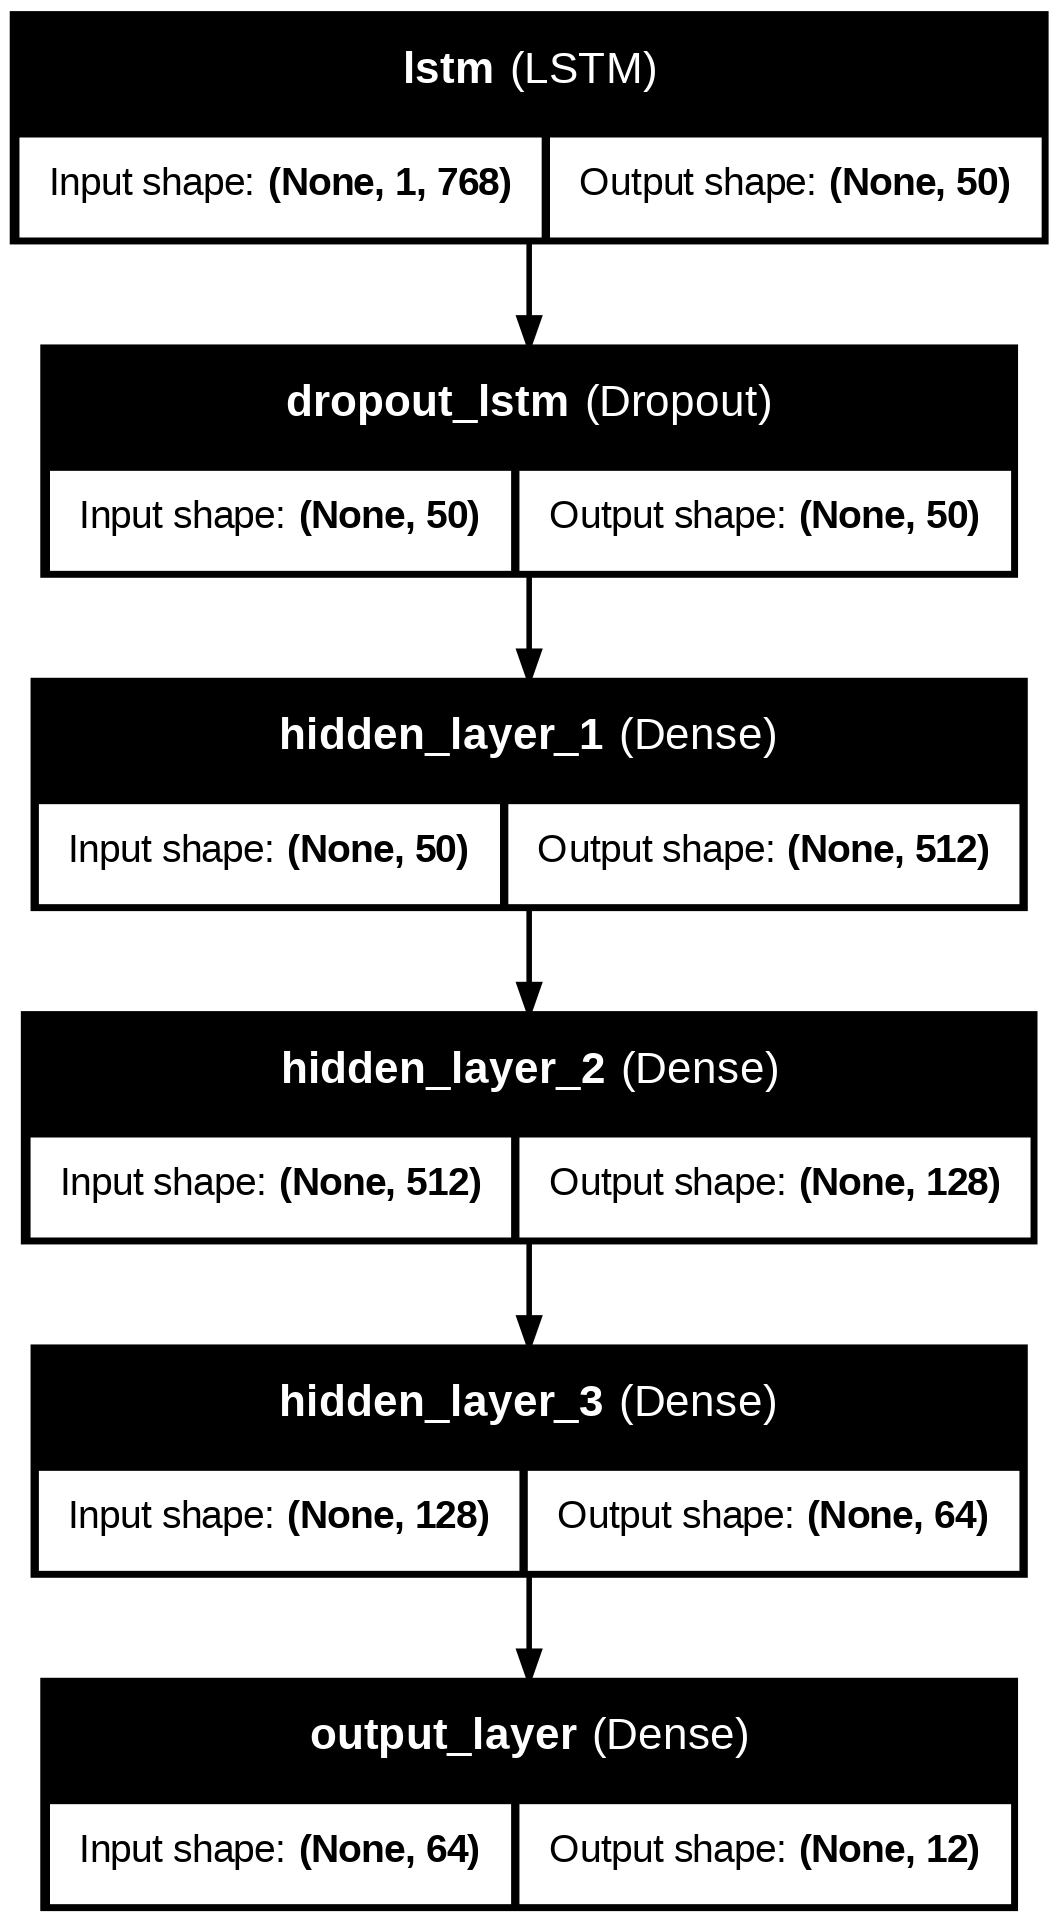

In [14]:
from tensorflow.keras.layers import Dense, Embedding, LSTM, SpatialDropout1D, Dropout, Bidirectional
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import plot_model

embed_dim = 768
lstm_out = 50

sa_model = Sequential()
sa_model.add(LSTM(lstm_out, input_shape=(1, 768), return_sequences=False, name='lstm'))
sa_model.add(Dropout(0.2, name='dropout_lstm'))
sa_model.add(Dense(512,activation='relu', name='hidden_layer_1'))
sa_model.add(Dense(128,activation='relu', name='hidden_layer_2'))
sa_model.add(Dense(64,activation='relu', name='hidden_layer_3'))
sa_model.add(Dense(num_labels,activation='softmax', name='output_layer'))

plot_model(sa_model, to_file='/kaggle/working/model_lstm.png', show_shapes=True, show_layer_names=True)



In [15]:
embed_model = AutoModel.from_pretrained(
    "indobenchmark/indobert-base-p1",
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

def generate_embedding(batch):
    encoded = tokenizer(batch['TEXT'], return_tensors="pt", padding=True, truncation=True, max_length=128)
    with torch.no_grad():
        return embed_model(**encoded).last_hidden_state[:, 0, :].squeeze().numpy()

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

In [16]:
def embed_text(x):
    encoded = tokenizer(x, return_tensors="pt", padding=True, truncation=True, max_length=128)
    with torch.no_grad():
        return embed_model(**encoded).last_hidden_state[:, 0, :].squeeze().numpy()
x_train = [embed_text(x) for x in x_train]

In [17]:
from datasets import Dataset, DatasetDict
from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

all_fold_metrics = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

x_train = np.array(x_train).reshape(-1, 1, 768)

# x_train = np.array(x_train)
y_train = np.array(y_train)

for fold, (train_idx, val_idx) in enumerate(skf.split(x_train, y_train)):
    print(f"\n=== Fold {fold + 1} ===")
    x_tr, x_val = x_train[train_idx], x_train[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    sa_model = Sequential()
    sa_model.add(LSTM(lstm_out, input_shape=(1, 768), return_sequences=False))
    sa_model.add(Dropout(0.2))
    sa_model.add(Dense(512,activation='relu'))
    sa_model.add(Dense(128,activation='relu'))
    sa_model.add(Dense(64,activation='relu'))
    sa_model.add(Dense(num_labels,activation='softmax'))
    
    sa_model.compile(loss = 'sparse_categorical_crossentropy', optimizer='adam',metrics = ['accuracy'])
    early_stop = EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)

    hist = sa_model.fit(x_tr, y_tr, validation_data = (x_val, y_val), batch_size=32, epochs = 20, callbacks=[early_stop])

    val_loss, val_acc = sa_model.evaluate(x_val, y_val, verbose=0)

    fold_metrics = {
        "fold":         fold + 1,
        "val_loss":     val_loss,
        "val_accuracy": val_acc,
        "best_epoch":   np.argmax(hist.history["val_accuracy"]) + 1,
        "train_accuracy_at_best": hist.history["accuracy"][np.argmax(hist.history["val_accuracy"])],
    }
    all_fold_metrics.append(fold_metrics)
    sa_model.save(f"/kaggle/working/model_fold_{fold+1}.keras")
    
    print(f"Fold {fold + 1} metrics: {fold_metrics}")



=== Fold 1 ===
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
I0000 00:00:1779354505.664195      70 cuda_dnn.cc:529] Loaded cuDNN version 91002


113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.4250 - loss: 2.0765 - val_accuracy: 0.4561 - val_loss: 1.9330
Epoch 2/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4511 - loss: 1.9051 - val_accuracy: 0.4616 - val_loss: 1.7824
Epoch 3/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4815 - loss: 1.7485 - val_accuracy: 0.4638 - val_loss: 1.6925
Epoch 4/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4856 - loss: 1.6522 - val_accuracy: 0.4783 - val_loss: 1.6670
Epoch 5/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4746 - loss: 1.6285 - val_accuracy: 0.4994 - val_loss: 1.6053
Epoch 6/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5068 - loss: 1.5499 - val_accuracy: 0.5161 - val_loss: 1.5529
Epoch 7/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5268 - loss: 1.4896 - val_accuracy: 0.5028 - val_loss: 1.5626
Epoch 8/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5299 - loss: 1.4594 - val_accuracy: 0.4994 - val_

In [18]:
res_df = pd.DataFrame(all_fold_metrics)
print("\n===== LSTM IndoBERT Per-Fold Metrics =====")
print(res_df)

print("\n===== Mean =====")

for col in res_df.columns:
    mean = res_df[col].mean()
    print(f"{col}: {mean:.4f}")


===== LSTM IndoBERT Per-Fold Metrics =====
   fold  val_loss  val_accuracy  best_epoch  train_accuracy_at_best
0     1  1.353372      0.558398          14                0.585305
1     2  1.217005      0.589544          17                0.610353
2     3  1.264369      0.571270          15                0.602393
3     4  1.348221      0.559020          10                0.563996
4     5  1.397854      0.565702           9                0.528381

===== Mean =====
fold: 3.0000
val_loss: 1.3162
val_accuracy: 0.5688
best_epoch: 13.0000
train_accuracy_at_best: 0.5781


In [19]:
import tensorflow as tf
print("\n===== Ensemble Testing =====")

all_fold_preds = []

for fold in range(5):
    pred_model = tf.keras.models.load_model(f"model_fold_{fold+1}.keras")

    x_test_ens = np.array([embed_text(x) for x in x_test]).reshape(-1, 1, 768)
    preds = pred_model.predict(x_test_ens, verbose=0)
    all_fold_preds.append(preds)

ensemble_preds = np.mean(all_fold_preds, axis=0)
final_labels   = np.argmax(ensemble_preds, axis=1)



===== Ensemble Testing =====


Ensemble Accuracy: 0.5260

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.03      0.06        30
           1       0.58      0.44      0.50        25
           2       0.78      0.61      0.68        23
           3       0.00      0.00      0.00         7
           4       0.71      0.24      0.36        50
           5       0.00      0.00      0.00         8
           6       0.52      0.39      0.45        28
           7       0.59      0.54      0.57        35
           8       0.49      0.87      0.62       198
           9       0.00      0.00      0.00        26
          10       0.56      0.20      0.29        25
          11       0.78      0.40      0.53        45

    accuracy                           0.53       500
   macro avg       0.46      0.31      0.34       500
weighted avg       0.53      0.53      0.47       500



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


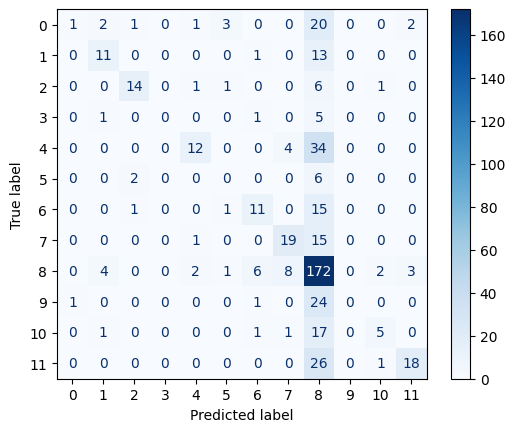

In [20]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

print(f"Ensemble Accuracy: {accuracy_score(y_test, final_labels):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, final_labels))
cm = confusion_matrix(y_test, final_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(id2label.keys()))
disp.plot(cmap=plt.cm.Blues)
plt.show()


In [21]:
model = AutoModelForSequenceClassification.from_pretrained(
    "indobenchmark/indobert-base-p1",
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [22]:
X = df['TEXT'].apply(lambda x: x.replace('$',''))
y = df['LABEL']

x_train, x_test, y_train, y_test = train_test_split(X,y, random_state=42, test_size=0.1)

In [ ]:
from datasets import Dataset, DatasetDict
from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.utils import to_categorical

all_fold_metrics = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf.split(x_train, y_train)):
    print(f"\n=== Fold {fold + 1} ===")

    train_df = df.iloc[train_idx].reset_index(drop=True)
    val_df = df.iloc[val_idx].reset_index(drop=True)

    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)

    train_dataset = train_dataset.map(tokenize, batched=True)
    val_dataset = val_dataset.map(tokenize, batched=True)
    
    train_dataset = train_dataset.rename_column("LABEL", "labels")
    val_dataset = val_dataset.rename_column("LABEL", "labels")

    train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
    val_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

    dataset_dict = DatasetDict({
        'train': train_dataset,
        'val': val_dataset
    })

    training_args = TrainingArguments(
        output_dir=f"/kaggle/working/result/fold-{fold}",            
        eval_strategy="epoch",                      
        logging_strategy="epoch",
        save_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=5,
        weight_decay=0.05,
        save_total_limit=1,                        
        load_best_model_at_end=True,
        metric_for_best_model="eval_accuracy",
        greater_is_better=True,
        remove_unused_columns=False
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=dataset_dict["train"],
        eval_dataset=dataset_dict["val"],
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
    )
    
    trainer.train()
    val_metrics = trainer.evaluate(eval_dataset=dataset_dict["val"])
    train_metrics = trainer.evaluate(eval_dataset=dataset_dict["train"])

    best_step = int(trainer.state.best_model_checkpoint.split("-")[-1])
    steps_per_epoch = len(dataset_dict["train"]) // 16
    best_epoch = best_step // steps_per_epoch
    fold_metrics = {
        "fold": fold,
        "val_loss": round(val_metrics["eval_loss"], 6),
        "val_accuracy": round(val_metrics["eval_accuracy"], 6),
        "best_epoch": best_epoch,
        "train_accuracy_at_best": round(train_metrics["eval_accuracy"], 6),
    }
    all_fold_metrics.append(fold_metrics)
    print(f"Fold {fold + 1} metrics: {fold_metrics}")


In [24]:
res_df = pd.DataFrame(all_fold_metrics)
print("\n===== Fine-tuned IndoBERT Per-Fold Metrics =====")
print(res_df)

print("\n===== Mean =====")
numeric_cols = res_df.select_dtypes(include="number")
for col in numeric_cols.columns:
    mean = numeric_cols[col].mean()
    print(f"{col}: {mean:.4f}")


===== Fine-tuned IndoBERT Per-Fold Metrics =====
   fold  val_loss  val_accuracy  best_epoch  train_accuracy_at_best
0     0  1.785083      0.711902           1                0.854161
1     1  1.053343      0.845384           2                0.990259
2     2  0.197524      0.978842           0                0.975793
3     3  0.120930      0.985523           0                0.984140
4     4  0.147063      0.986637           1                0.996105

===== Mean =====
fold: 2.0000
val_loss: 0.6608
val_accuracy: 0.9017
best_epoch: 0.8000
train_accuracy_at_best: 0.9601


In [25]:

test = pd.DataFrame({
    'x':x_test, 'y':y_test
})


In [26]:
from transformers import pipeline

def get_model(model_path):
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    
    pipe = pipeline("text-classification", model=model, tokenizer=tokenizer)
    return pipe

In [27]:
import os

paths = []
for fold in os.listdir('/kaggle/working/result'):
    
    paths.append(f"/kaggle/working/result/{fold}/{os.listdir('/kaggle/working/result/' + fold)[0]}")
paths

['/kaggle/working/result/fold-3/checkpoint-113',
 '/kaggle/working/result/fold-2/checkpoint-113',
 '/kaggle/working/result/fold-0/checkpoint-339',
 '/kaggle/working/result/fold-1/checkpoint-565',
 '/kaggle/working/result/fold-4/checkpoint-226']

In [28]:
import tensorflow as tf
print("\n===== Ensemble Testing =====")

all_fold_preds = []

for path in paths:
    pred_model = get_model(path)
    model_probs = []
    outputs = pred_model(list(test['x']), top_k=12)
    for output in outputs:
        sorted_output = sorted(output, key=lambda x: x["label"])
        probs = [item["score"] for item in sorted_output]
        model_probs.append(probs)

    all_fold_preds.append(model_probs)

final_probs = np.mean(all_fold_preds, axis=0)
final_preds = np.argmax(final_probs, axis=1)         
# ensemble_preds = np.mean(all_fold_preds, axis=0)


===== Ensemble Testing =====


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Ensemble Accuracy: 0.9240

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        30
           1       0.96      1.00      0.98        25
           2       1.00      0.22      0.36        23
           3       0.86      0.86      0.86         7
           4       0.98      0.96      0.97        50
           5       1.00      0.62      0.77         8
           6       1.00      0.93      0.96        28
           7       0.73      1.00      0.84        35
           8       0.92      0.95      0.94       198
           9       0.93      1.00      0.96        26
          10       0.89      1.00      0.94        25
          11       1.00      1.00      1.00        45

    accuracy                           0.92       500
   macro avg       0.94      0.87      0.88       500
weighted avg       0.93      0.92      0.91       500



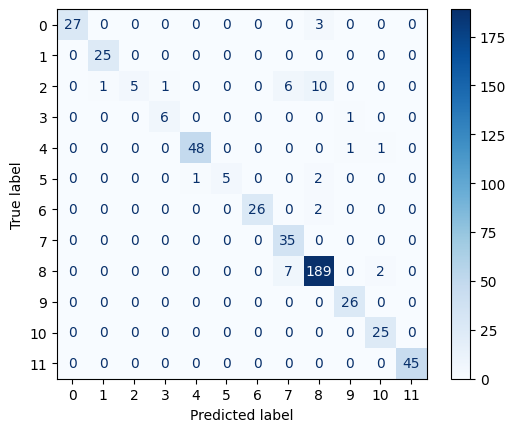

In [29]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

print(f"Ensemble Accuracy: {accuracy_score(test['y'], final_preds):.4f}")
print("\nClassification Report:")
print(classification_report(test['y'], final_preds))
cm = confusion_matrix(test['y'], final_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(id2label.keys()))
disp.plot(cmap=plt.cm.Blues)
plt.show()
